In [56]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [57]:
df = fetch_california_housing(as_frame=True)

print(df.frame.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [58]:
features = ["MedInc", "AveRooms", "AveBedrms", "HouseAge"]

X = df.frame[features].values
y = df.frame["MedHouseVal"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Shape of X_train: (16512, 4)
Shape of X_test: (4128, 4)
Shape of y_train: (16512,)
Shape of y_test: (4128,)


In [59]:
def Z_score(X):
    mew = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    return (X-mew) / sigma, mew, sigma

In [60]:
def compute_cost(X, y, w, b):
    m = X.shape[0]

    cost = np.dot(X, w) + b - y
    cost = np.sum(cost ** 2)
    cost = cost / (2 * m)
    return cost

In [61]:
def compute_gradient(X, y, w, b):

    dJ_dw = np.zeros(w.shape)
    dJ_db = 0

    m = X.shape[0]
    n = w.shape[0]

    for i in range(m):
        f_wb = np.dot(X[i], w) + b
        err = f_wb - y[i]
        for j in range(n):
            dJ_dw[j] += err * X[i][j]
        dJ_db += err

    dJ_dw = dJ_dw / m
    dJ_db = dJ_db / m

    return dJ_dw, dJ_db

In [62]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, cost, gradient):

    J_history = [cost(X, y, w_in, b_in)]
    w = w_in
    b = b_in

    for i in range(num_iters):

        dj_dw, dj_db = gradient(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000:
            J_history.append(cost(X, y, w, b))

    return w, b, J_history

In [63]:
X_train, mew, sigma = Z_score(X_train)

w = np.zeros(X_train.shape[1])
b = 0
num_iters = 1000
alpha = 10e-3

w,b,J_history = gradient_descent(X_train, y_train, w, b, alpha, num_iters, compute_cost, compute_gradient)

Text(0.5, 1.0, 'Training Data')

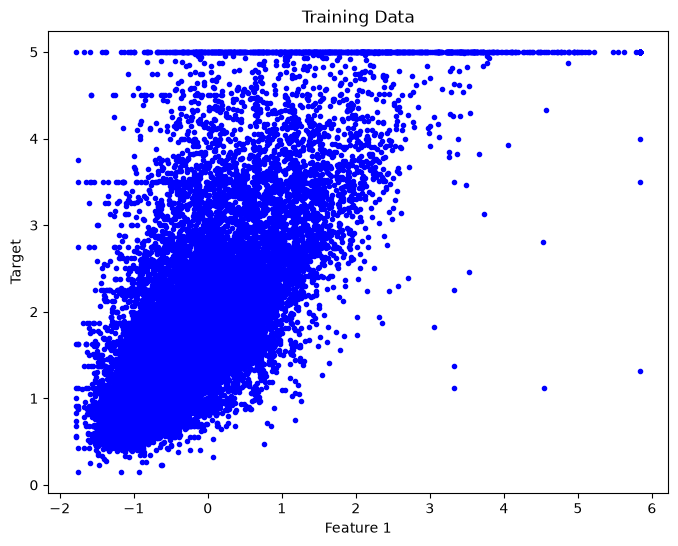

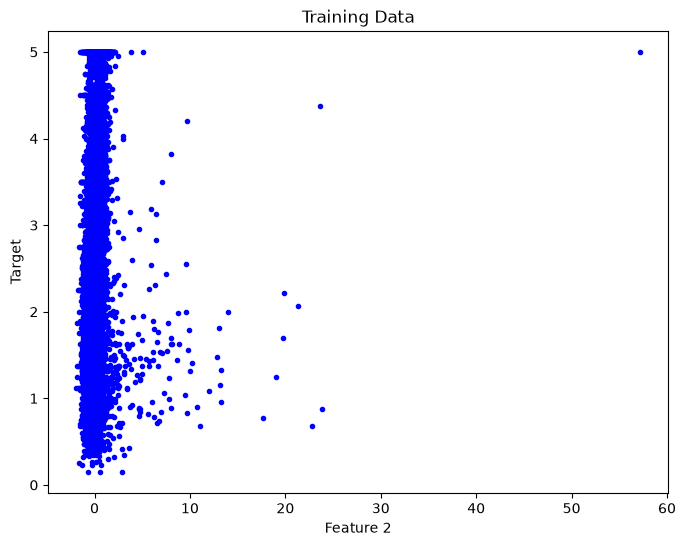

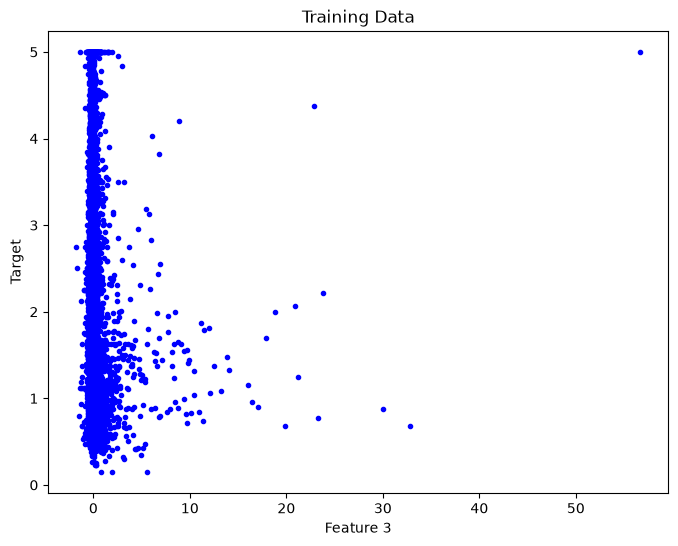

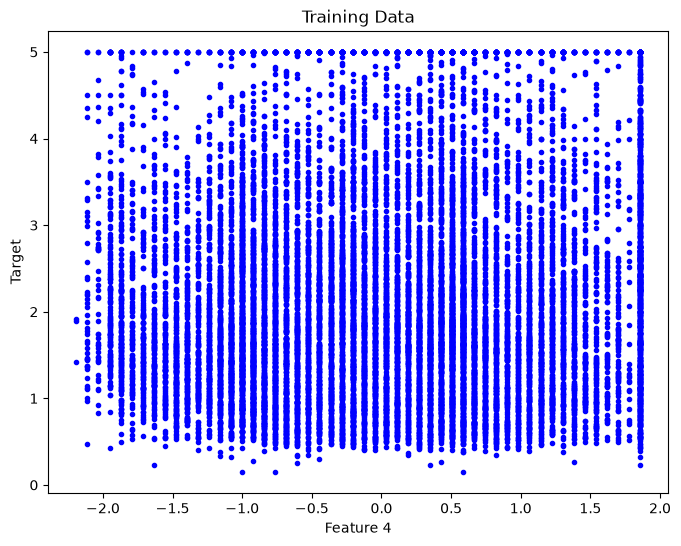

In [64]:
plt.figure(figsize=(8,6))
plt.plot(X_train[:,0], y_train, 'b.', label='Training data')
plt.xlabel('Feature 1')
plt.ylabel('Target')
plt.title('Training Data')

plt.figure(figsize=(8,6))
plt.plot(X_train[:,1], y_train, 'b.', label='Training data')
plt.xlabel('Feature 2')
plt.ylabel('Target')
plt.title('Training Data')

plt.figure(figsize=(8,6))
plt.plot(X_train[:,2], y_train, 'b.', label='Training data')
plt.xlabel('Feature 3')
plt.ylabel('Target')
plt.title('Training Data')

plt.figure(figsize=(8,6))
plt.plot(X_train[:,3], y_train, 'b.', label='Training data')
plt.xlabel('Feature 4')
plt.ylabel('Target')
plt.title('Training Data')

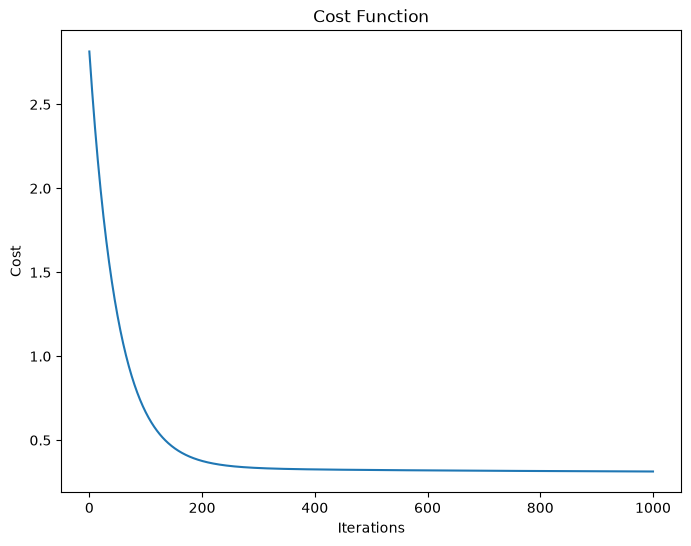

In [65]:
plt.figure(figsize=(8,6))
plt.plot(J_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Function")
plt.show()

In [66]:
print(f"Final weights: {w}")
print(f"Final bias: {b}")

Final weights: [ 0.89200403 -0.19685901  0.1659741   0.21204593]
Final bias: 2.0718574888450276


In [67]:
X_test = (X_test - mew) / sigma
y_predict = np.dot(X_test, w) + b
print(f"predicted values ={y_predict}")

predicted values =[1.05479975 1.53288087 2.43217975 ... 4.31089468 1.65149302 1.81763801]


In [68]:
error = mean_absolute_error(y_test, y_predict)
squarederror = mean_squared_error(y_test, y_predict)
print(f"Mean Absolute Error: {error}")
print(f"Mean Squared Error: {squarederror}")

Mean Absolute Error: 0.5930040294157818
Mean Squared Error: 0.6416969834120057
